In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

image_dir = Path("/content/drive/MyDrive/cxr_project/sample_images")

if not image_dir.exists():
    raise FileNotFoundError(f"폴더 경로를 확인해줘: {image_dir}")

image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg"}
)

print("이미지 개수:", len(image_paths))

for path in image_paths:
    print(path.name)

이미지 개수: 1
02aa804e-bde0afdd-112c0b34-7bc16630-4e384014.jpg


파일명: 02aa804e-bde0afdd-112c0b34-7bc16630-4e384014.jpg
크기(가로, 세로): (2544, 3056)
색상 모드: L



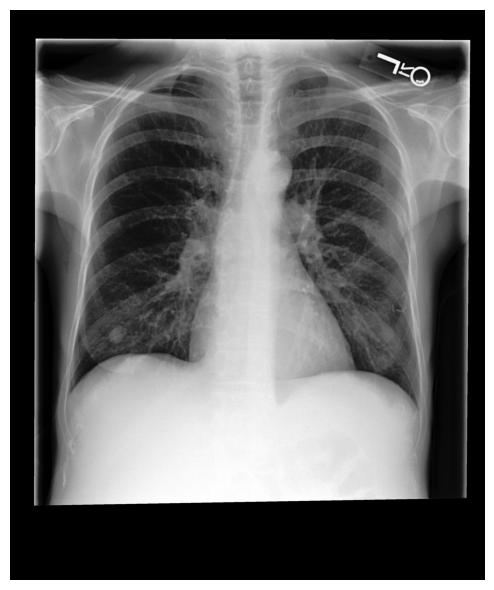

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

sample_paths = image_paths[:2]

if not sample_paths:
    raise ValueError("지정한 폴더에 JPG 이미지가 없어.")

fig, axes = plt.subplots(
    1, len(sample_paths),
    figsize=(6 * len(sample_paths), 6),
    squeeze=False
)

for ax, path in zip(axes[0], sample_paths):
    with Image.open(path) as img:
        print(f"파일명: {path.name}")
        print(f"크기(가로, 세로): {img.size}")
        print(f"색상 모드: {img.mode}\n")

        ax.imshow(img.convert("L"), cmap="gray", vmin=0, vmax=255)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

metadata_path = (
    "/content/drive/MyDrive/cxr_project/sample_images/"
    "mimic-cxr-2.0.0-metadata.csv.gz"
)

metadata = pd.read_csv(
    metadata_path,
    usecols=["dicom_id", "ViewPosition"]
)

# 다운로드한 이미지의 파일명에서 식별자 추출
sample_df = pd.DataFrame({
    "dicom_id": [p.stem for p in image_paths],
    "image_path": [str(p) for p in image_paths]
})

# 이미지와 촬영 방향 연결
sample_df = sample_df.merge(
    metadata,
    on="dicom_id",
    how="left",
    validate="many_to_one"
)

display(sample_df[["dicom_id", "ViewPosition"]])

,dicom_id,ViewPosition
0,02aa804e-bde0afdd-112c0b34-7bc16630-4e384014,PA


In [ ]:
frontal_df = sample_df[
    sample_df["ViewPosition"].isin(["AP", "PA"])
].copy()

frontal_paths = [
    Path(path) for path in frontal_df["image_path"]
]

print("전체 이미지:", len(sample_df))
print("AP·PA 이미지:", len(frontal_paths))

전체 이미지: 1
AP·PA 이미지: 1


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

def resize_with_padding(image, target_size=224):
    image = image.convert("L")  # 흑백으로 변환
    width, height = image.size

    # 긴 쪽 길이를 기준으로 정사각형 캔버스 생성
    side = max(width, height)
    padded = Image.new("L", (side, side), color=0)

    # 원본 이미지를 가운데 배치
    left = (side - width) // 2
    top = (side - height) // 2
    padded.paste(image, (left, top))

    # 정사각형 전체를 목표 크기로 조정
    resized = padded.resize(
        (target_size, target_size),
        resample=Image.Resampling.BILINEAR
    )

    return resized


원본 크기(가로, 세로): (2544, 3056)
전처리 후 크기: (224, 224)


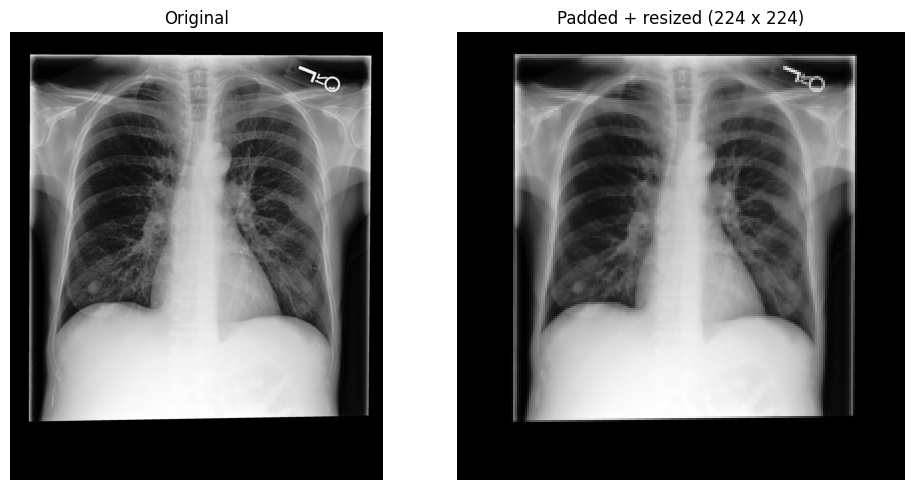

In [ ]:
if not frontal_paths:
    raise ValueError("AP·PA 이미지가 없어. 촬영 방향 필터를 확인해줘.")

with Image.open(frontal_paths[0]) as img:
    original = img.convert("L")

processed = resize_with_padding(original, target_size=224)

print("원본 크기(가로, 세로):", original.size)
print("전처리 후 크기:", processed.size)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(processed, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Padded + resized (224 x 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# 이미지를 실수형 배열로 변환하고 255로 나누기
normalized = np.asarray(processed, dtype=np.float32) / 255.0

print("배열 크기:", normalized.shape)
print("자료형:", normalized.dtype)
print("최솟값:", normalized.min())
print("최댓값:", normalized.max())

배열 크기: (224, 224)
자료형: float32
최솟값: 0.0
최댓값: 0.99607843


In [ ]:
import torch

image_tensor = torch.from_numpy(normalized).unsqueeze(0)

print("텐서 크기:", image_tensor.shape)
print("자료형:", image_tensor.dtype)

텐서 크기: torch.Size([1, 224, 224])
자료형: torch.float32


In [ ]:
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

target_labels = ["Cardiomegaly", "Edema", "Pleural Effusion"]

class CXRDataset(Dataset):
    def __init__(self, dataframe, image_size=224):
        self.df = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        # 1. 이미지 읽기 → 패딩 → 크기 조정
        with Image.open(row["image_path"]) as image:
            processed = resize_with_padding(
                image,
                target_size=self.image_size
            )

        # 2. 0~1 정규화 → 이미지 텐서 변환
        array = np.asarray(processed, dtype=np.float32) / 255.0
        image_tensor = torch.from_numpy(array).unsqueeze(0)

        # 3. ★ 라벨을 만드는 부분
        # 원본 0 → 음성 0
        # 원본 1 → 양성 1
        # 원본 -1 → 불확실 2
        class_map = {0: 0, 1: 1, -1: 2}
        label_ids = row[target_labels].map(class_map)

        if label_ids.isna().any():
            raise ValueError("최종 라벨 연결과 라벨 값을 확인해줘.")

        label_tensor = torch.tensor(
            label_ids.to_numpy(dtype=np.int64),
            dtype=torch.long
        )

        # 4. 이미지와 세 소견의 정답을 함께 반환
        return image_tensor, label_tensor

In [ ]:
# 최종 라벨이 연결된 이미지만 선택
dataset_df = linked_df[
    linked_df["label_match"].eq("both")
].copy()

if dataset_df.empty:
    print("최종 라벨이 연결된 이미지가 없어. 포함 대상 샘플을 추가해줘.")

else:
    dataset = CXRDataset(dataset_df)

    loader = DataLoader(
        dataset,
        batch_size=4,
        shuffle=False,
        num_workers=0
    )

    images, labels = next(iter(loader))

    print("이미지 배치 크기:", images.shape)
    print("라벨 배치 크기:", labels.shape)
    print("라벨 자료형:", labels.dtype)
    print("라벨 값:", labels)

이미지 배치 크기: torch.Size([3, 1, 224, 224])
라벨 배치 크기: torch.Size([3, 3])
라벨 자료형: torch.int64
라벨 값: tensor([[0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]])


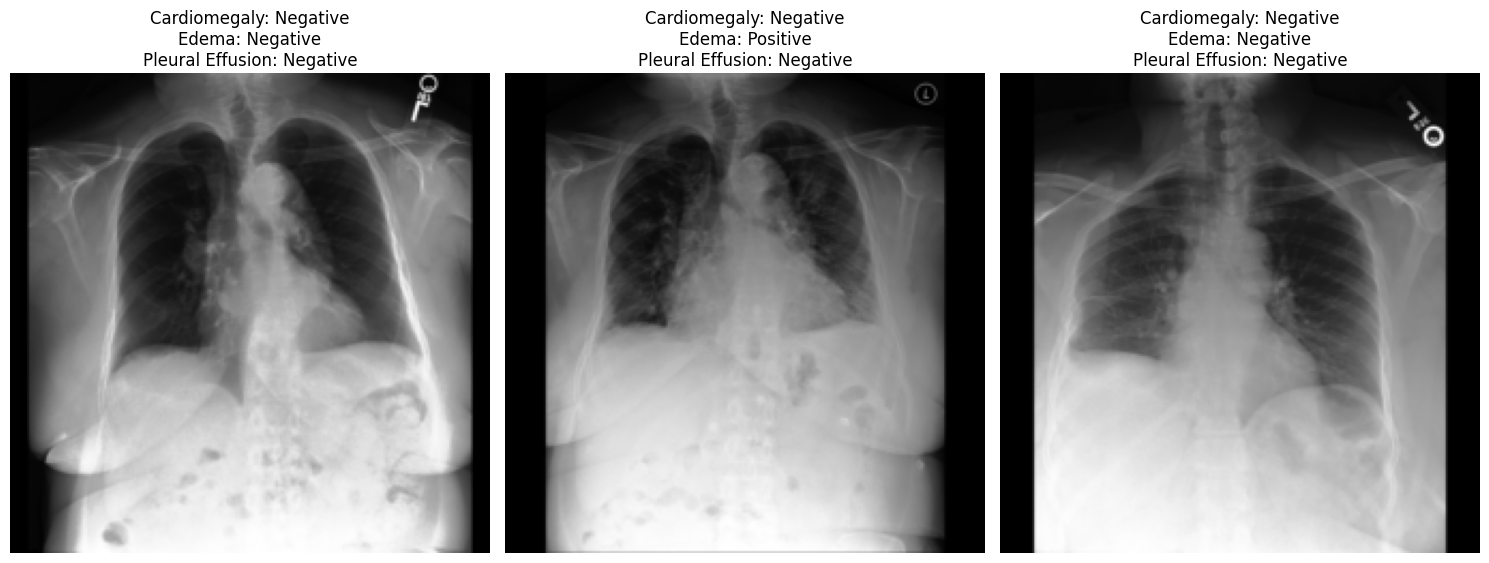

In [ ]:
import matplotlib.pyplot as plt

class_names = ["Negative", "Positive", "Uncertain"]
finding_names = ["Cardiomegaly", "Edema", "Pleural Effusion"]

fig, axes = plt.subplots(
    1, len(images),
    figsize=(5 * len(images), 6),
    squeeze=False
)

for ax, image, label in zip(axes[0], images, labels):
    ax.imshow(image[0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)

    title = "\n".join(
        f"{finding}: {class_names[value]}"
        for finding, value in zip(finding_names, label.tolist())
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()